# **Object and face detection**

#### **1. Simple object detection with connected components**
- Connected component analysis groups pixels belonging to the same object.

- `skimage.measure.label` assigns unique labels to connected regions.

- `skimage.measure.regionprops` extracts useful information: area, bounding box, centroid, etc.

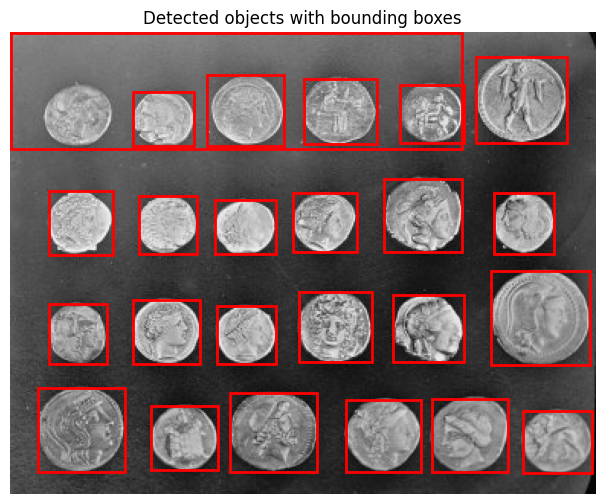

In [ ]:
from skimage import data, color, filters, measure
import matplotlib.pyplot as plt
import matplotlib.patches as patches

image = data.coins()

threshold = filters.threshold_otsu(image)
binary = image > threshold

labels = measure.label(binary)

regions = measure.regionprops(labels)

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(image, cmap='gray')

for region in regions:
    if region.area > 100 and region.area < 5000:  # Filter regions by area
        minr, minc, maxr, maxc = region.bbox
        rect = patches.Rectangle((minc, minr),
                                 maxc - minc, maxr - minr,
                                 fill=False, edgecolor='red', linewidth=2)
        ax.add_patch(rect)

plt.title("Detected objects with bounding boxes")
plt.axis('off')
plt.show()


#### **2. Face detection**
- scikit-image provides `skimage.feature.Cascade` for object detection using pretrained Haar cascades.

- Load a cascade model for frontal face detection.

- Detect face bounding boxes in an image.

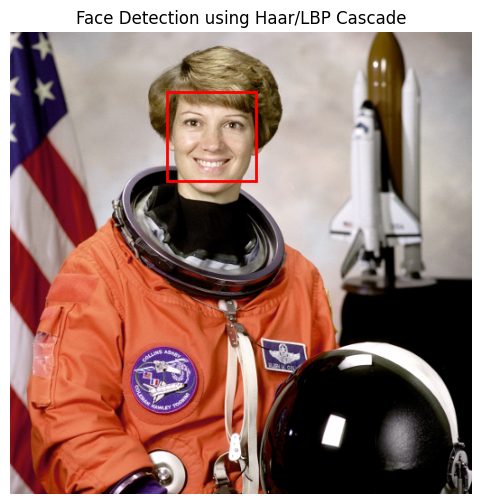

In [13]:
from skimage import data
from skimage.feature import Cascade
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# STEP 1: Get path to the trained cascade model for faces (frontal profile)
# This model was previously trained on thousands of face and non-face images.
trained_file = data.lbp_frontal_face_cascade_filename()

# STEP 2: Initialize the detector
detector = Cascade(trained_file)

# STEP 3: Load the image (e.g., an astronaut photo)
image = data.astronaut()

# STEP 4: Detect faces in the image
# scale_factor=1.1 -> how much we scale the image when searching for faces of different sizes
# step_ratio=1 -> density of sliding window
# min_size=(60, 60), max_size=(300, 300) -> range of face sizes to search for in pixels
detected = detector.detect_multi_scale(img=image,
                                       scale_factor=1.1,
                                       step_ratio=1,
                                       min_size=(60, 60),
                                       max_size=(300, 300))

# STEP 5: Plot the results
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image)

for patch in detected:
    # detector returns a dictionary/structure containing:
    # r (row/y), c (column/x), width (width), height (height)
    ax.add_patch(
        patches.Rectangle(
            (patch['c'], patch['r']),
            patch['width'],
            patch['height'],
            fill=False,
            edgecolor='red',
            linewidth=2
        )
    )

plt.title("Face Detection using Haar/LBP Cascade")
plt.axis('off')
plt.show()